# Calculate $\gamma_{thermal}$ and $\gamma_{spatial}$

This shows how the thermal and spatial baseline contributions to coherence are calculated, then divided out of the NISAR coherence to leave $\gamma_{temporal}$. 

In [1]:
import numpy as np
import xarray as xr
import rioxarray  # noqa: F401
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo 
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.download import build_snr_timeseries, interpolate_radar_grid_to_dem
from scripts.coherence import thermal_coherence, spatial_coherence

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


First, we setup logging to get useful information and error messages. 

In [2]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True 
)

Open the data cubes that were saved by the download notebook. 

In [3]:
data_dir = "../data/"
track = 19
frame = 21

nisar_20m = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/gunw_20m.zarr')
nisar_80m = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/gunw_80m.zarr')

Next, load the ASO snow depth and use its footprint to mask the cubes. 

In [4]:
aso = xr.open_dataarray(data_dir + 'aso/er_20260318/ASO_EastRiver_2026Mar18_snowdepth_3m.tif')

nisar_80m = nisar_80m.where(aso.rio.reproject_match(nisar_80m).notnull())
nisar_20m = nisar_20m.where(aso.rio.reproject_match(nisar_20m).notnull())

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/google/api_core/_python_version_support.py:255: FutureWarning: You are using a Python version (3.11.15) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


The start and end time of each date pair are stored in the cube. 

In [5]:
starts = nisar_80m['start'].values
ends = nisar_80m['end'].values

In [26]:
print(starts)

['2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-11-23T05:11:37.978947000' '2025-11-23T05:11:37.978947000'
 '2025-12-05T05:11:38.578947000' '2025-12-05T05:11:38.578947000'
 '2025-12-05T05:11:38.578947000' '2025-12-05T05:11:38.578947000'
 '2025-12-05T05:11:38.578947000' '2025-12-05T05:11:38.578947000'
 '2025-12-05T05:11:38.578

## $\gamma_{thermal}$

Thermal noise coherence depends on the SNR of the two acquisitions in each pair. We get the SNR from the backscatter and NEBZ files. 

In [20]:
bs_files = [item.resolve() for item in Path(data_dir + f'nisar/east_river/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}').rglob('*backscatter*')]
nebz_files = [item.resolve() for item in Path(data_dir + f'nisar/east_river/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}').rglob('*NEBZ*')]
print(f'Found {len(bs_files)} backscatter files and {len(nebz_files)} NEBZ files')

Found 26 backscatter files and 26 NEBZ files


Build a time series of SNR from the files. The time zone offset needs to match the cubes. 

In [21]:
snr = build_snr_timeseries(bs_files, nebz_files, utc_offset_hours=-7)
# snr = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/snr.zarr')
# snr = snr.set_coords("spatial_ref")
snr

Resample the SNR to 20 m and mask it to the ASO footprint. 

In [12]:
res = 100

snr_dwn = snr.rio.reproject(
    snr.rio.crs,
    resolution=res
)
snr_dwn = snr_dwn.where(aso.rio.reproject_match(snr_dwn).notnull())

KeyboardInterrupt: 

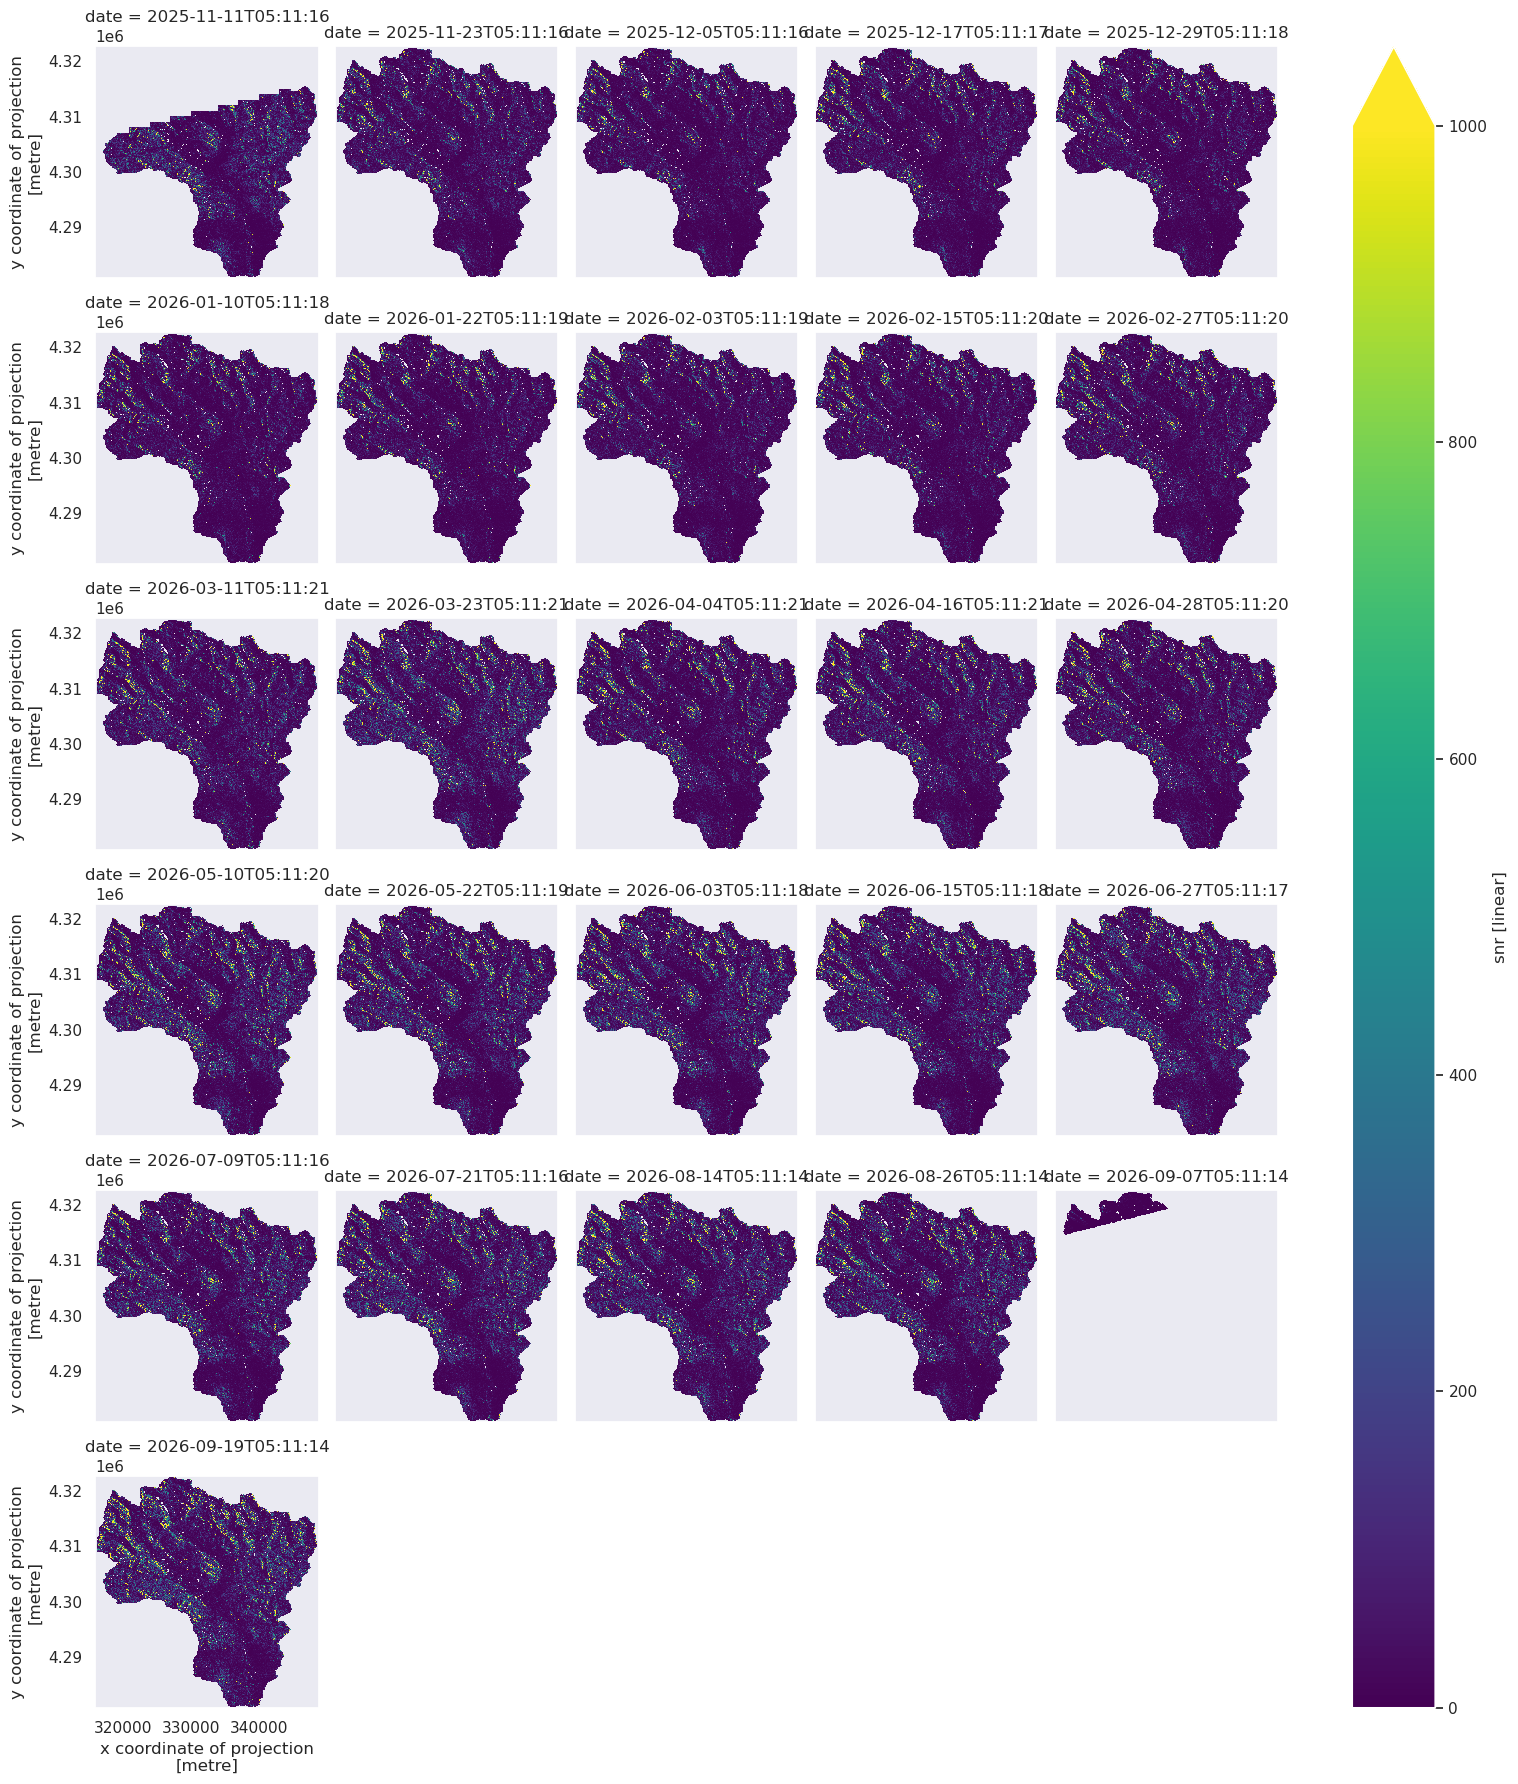

In [ ]:
snr_dwn.plot(col='date', col_wrap=5, vmin=0, vmax=1000)

Calculate $\gamma_{thermal}$ for every date pair, then plot it. 

In [13]:
gamma_thermal = thermal_coherence(snr, starts, ends).squeeze()
gamma_thermal = gamma_thermal.rio.write_crs(snr.rio.crs)

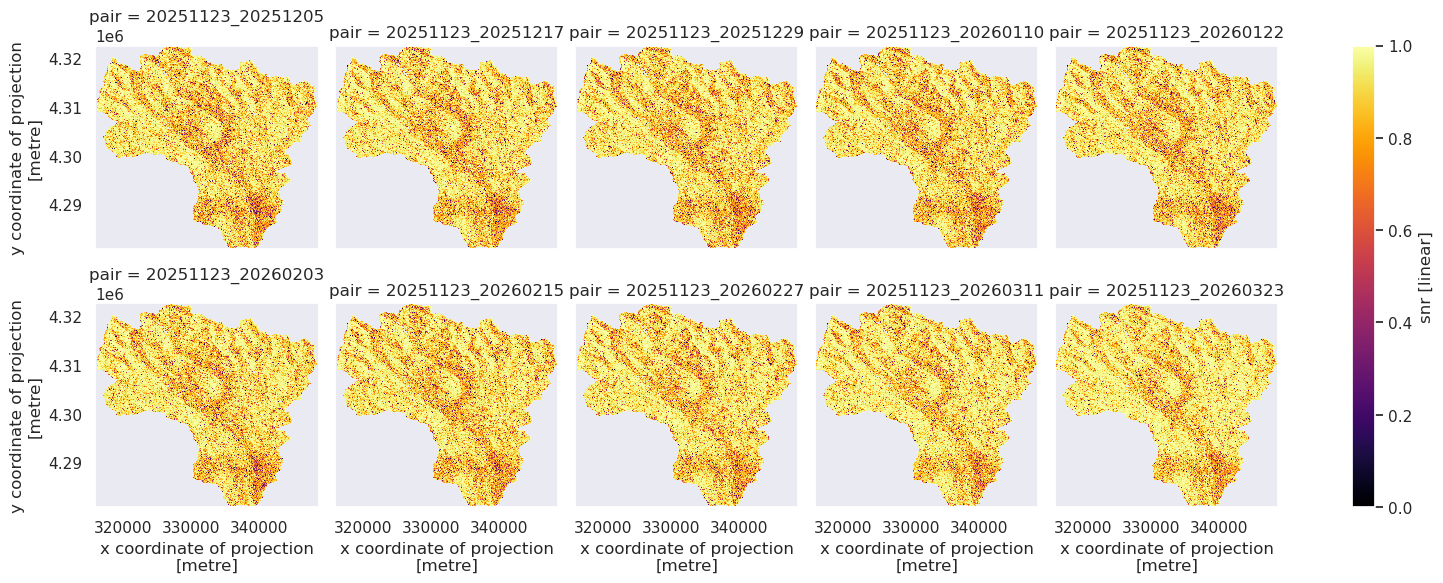

In [34]:
gamma_thermal.isel(pair=slice(0,10)).plot(col='pair', col_wrap=5, vmin=0, vmax=1, cmap='inferno')

## $\gamma_{spatial}$

Spatial baseline coherence depends on the perpendicular baseline, incidence angle and slant range. These are interpolated onto the DEM. 

In [14]:
inc_files = [item.resolve() for item in Path(data_dir + f'nisar/east_river/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}').rglob('*incidence_angle*')]
bl_files = [item.resolve() for item in Path(data_dir + f'nisar/east_river/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}').rglob('*perpendicular_baseline*')]
r_files = [item.resolve() for item in Path(data_dir + f'nisar/east_river/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}').rglob('*reference_slant_range*')]
print(f'Found {len(inc_files)} incidence angle files, {len(bl_files)} perp baseline files, and {len(r_files)} slant range files')

Found 27 incidence angle files, 27 perp baseline files, and 27 slant range files


Interpolate each radar grid layer onto the 80 m DEM. 

In [15]:
nisar_80m = nisar_80m.set_coords("spatial_ref")
nisar_20m = nisar_20m.set_coords("spatial_ref")

nisar_80m

<xarray.Dataset> Size: 884MB
Dimensions:         (y: 566, x: 433, band: 1, pair: 300)
Coordinates:
  * y               (y) float64 5kB 4.324e+06 4.324e+06 ... 4.279e+06 4.279e+06
  * x               (x) float64 3kB 3.151e+05 3.152e+05 ... 3.496e+05 3.496e+05
  * band            (band) int64 8B 1
  * pair            (pair) <U17 20kB '20251123_20251205' ... '20260919_20261001'
    end             (pair) datetime64[ns] 2kB dask.array<chunksize=(16,), meta=np.ndarray>
    start           (pair) datetime64[ns] 2kB dask.array<chunksize=(16,), meta=np.ndarray>
    spatial_ref     int64 8B 0
Data variables:
    canopy_2021     (y, x, band) float32 980kB dask.array<chunksize=(283, 217, 1), meta=np.ndarray>
    coherence       (pair, y, x, band) float32 294MB dask.array<chunksize=(16, 256, 256, 1), meta=np.ndarray>
    coherence_true  (pair, y, x, band) float64 588MB dask.array<chunksize=(16, 256, 256, 1), meta=np.ndarray>
    elevation       (y, x, band) float32 980kB dask.array<chunksize=(283, 217, 1), meta=np.ndarray>
Attributes:
    crs:      EPSG:32613
    track:    19
    frame:    21

In [16]:
baselines = interpolate_radar_grid_to_dem(nisar_80m['elevation'], bl_files, utc_offset_hours=-7)
thetas = interpolate_radar_grid_to_dem(nisar_80m['elevation'], inc_files, utc_offset_hours=-7)
rs = interpolate_radar_grid_to_dem(nisar_80m['elevation'], r_files, utc_offset_hours=-7)

Calculate $\gamma_{spatial}$, then plot it. 

In [17]:
res = 3 
wvl = .24
gamma_spatial = spatial_coherence(baselines, thetas, rs, res, wvl).squeeze()


In [ ]:

gamma_spatial.plot(col='pair', col_wrap=5)

## $\gamma_{temporal}$

Dividing the coherence by $\gamma_{thermal}$ and $\gamma_{spatial}$ leaves $\gamma_{temporal}$. 

In [19]:
nisar_80m['gamma_thermal'] = gamma_thermal.rio.reproject_match(nisar_80m, resampling=Resampling.bilinear) 
nisar_80m['gamma_spatial'] = gamma_spatial.rio.reproject_match(nisar_80m, resampling=Resampling.bilinear)


MemoryError: Unable to allocate 61.2 GiB for an array with shape (300, 8360, 6550) and data type float32

In [ ]:
nisar_20m['gamma_thermal'] = gamma_thermal.rio.reproject_match(nisar_20m, resampling=Resampling.bilinear) 
nisar_20m['gamma_spatial'] = gamma_spatial.rio.reproject_match(nisar_20m, resampling=Resampling.bilinear)


In [ ]:
nisar_80m['gamma_temporal_uncorrected'] = nisar_80m['coherence'] / (nisar_80m['gamma_thermal'] * nisar_80m['gamma_spatial'])
nisar_20m['gamma_temporal_uncorrected'] = nisar_20m['coherence'] / (nisar_20m['gamma_thermal'] * nisar_20m['gamma_spatial'])

In [ ]:
nisar_80m['gamma_temporal'] = nisar_80m['coherence_true'] / (nisar_80m['gamma_thermal'] * nisar_80m['gamma_spatial'])
nisar_20m['gamma_temporal'] = nisar_20m['coherence_true'] / (nisar_20m['gamma_thermal'] * nisar_20m['gamma_spatial'])

In [57]:
# nisar_80m['gamma_temporal'].where(nisar_80m['gamma_thermal'] < nisar_80m['coherence_true']).plot(col='pair', col_wrap=5, cmap='inferno')
# nisar_20m['gamma_temporal'].where(nisar_20m['gamma_thermal'] < nisar_20m['coherence_true']).plot(col='pair', col_wrap=5, cmap='inferno')

Plot $\gamma_{temporal}$ for both grids. 

In [32]:
more_than_1 = nisar_80m['gamma_thermal'] < nisar_80m['coherence_true'] 
print(more_than_1.sum(dim=["y", "x"]).to_pandas())
print(nisar_80m['gamma_thermal'].where(more_than_1).mean(dim=["y", "x"]).to_pandas())

band                 1
pair                  
20251123_20251205   30
20251205_20251217   30
20251217_20251229   53
20251229_20260110  622
20260110_20260122  646
20260122_20260203   38
20260203_20260215    3
20260215_20260227   77
20260227_20260311   14
20260311_20260323   22
20260323_20260404   18
20260404_20260416  115
20260416_20260428   72
20260428_20260510   32
band                      1
pair                       
20251123_20251205  0.807889
20251205_20251217  0.778183
20251217_20251229  0.779302
20251229_20260110  0.785455
20260110_20260122  0.789253
20260122_20260203  0.750952
20260203_20260215  0.755478
20260215_20260227  0.778992
20260227_20260311  0.766325
20260311_20260323  0.801367
20260323_20260404  0.823317
20260404_20260416  0.807289
20260416_20260428  0.817628
20260428_20260510  0.818366


In [33]:
more_than_1 = nisar_20m['gamma_thermal'] < nisar_20m['coherence_true'] 
print(more_than_1.sum(dim=["y", "x"]).to_pandas())
print(nisar_20m['gamma_thermal'].where(more_than_1).mean(dim=["y", "x"]).to_pandas())

band                   1
pair                    
20251123_20251205  12180
20251205_20251217  11477
20251217_20251229  16337
20251229_20260110  60327
20260110_20260122  57040
20260122_20260203  22382
20260203_20260215   5698
20260215_20260227  14811
20260227_20260311   9125
20260311_20260323   3612
20260323_20260404   4083
20260404_20260416  15967
20260416_20260428  12621
20260428_20260510   9127
band                      1
pair                       
20251123_20251205  0.612404
20251205_20251217  0.629471
20251217_20251229  0.647728
20251229_20260110  0.685515
20260110_20260122  0.682108
20260122_20260203  0.635655
20260203_20260215  0.594503
20260215_20260227  0.661384
20260227_20260311  0.668315
20260311_20260323  0.654909
20260323_20260404  0.647741
20260404_20260416  0.680475
20260416_20260428  0.675269
20260428_20260510  0.627414


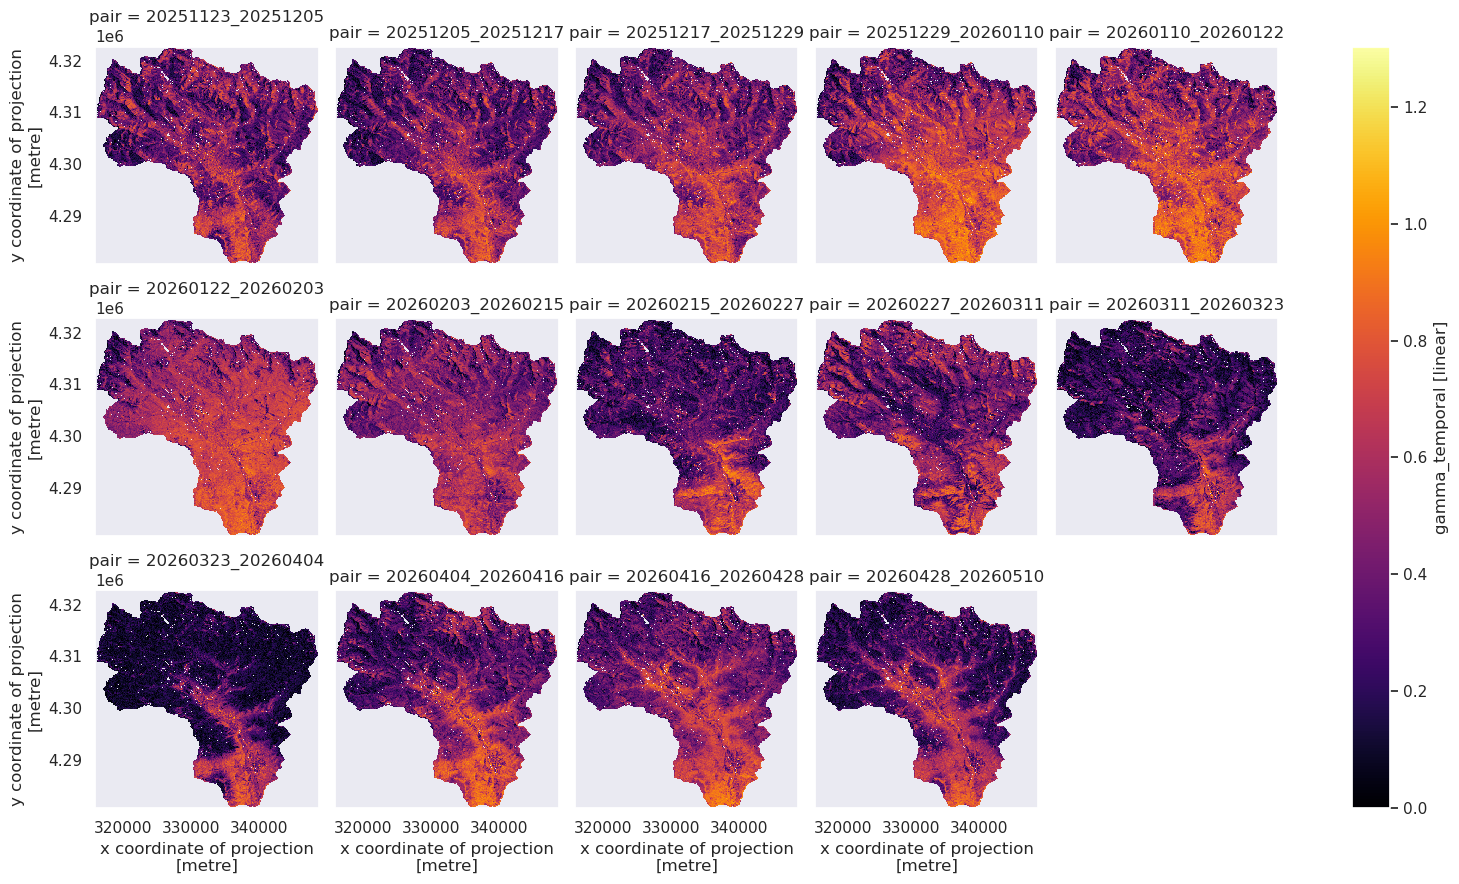

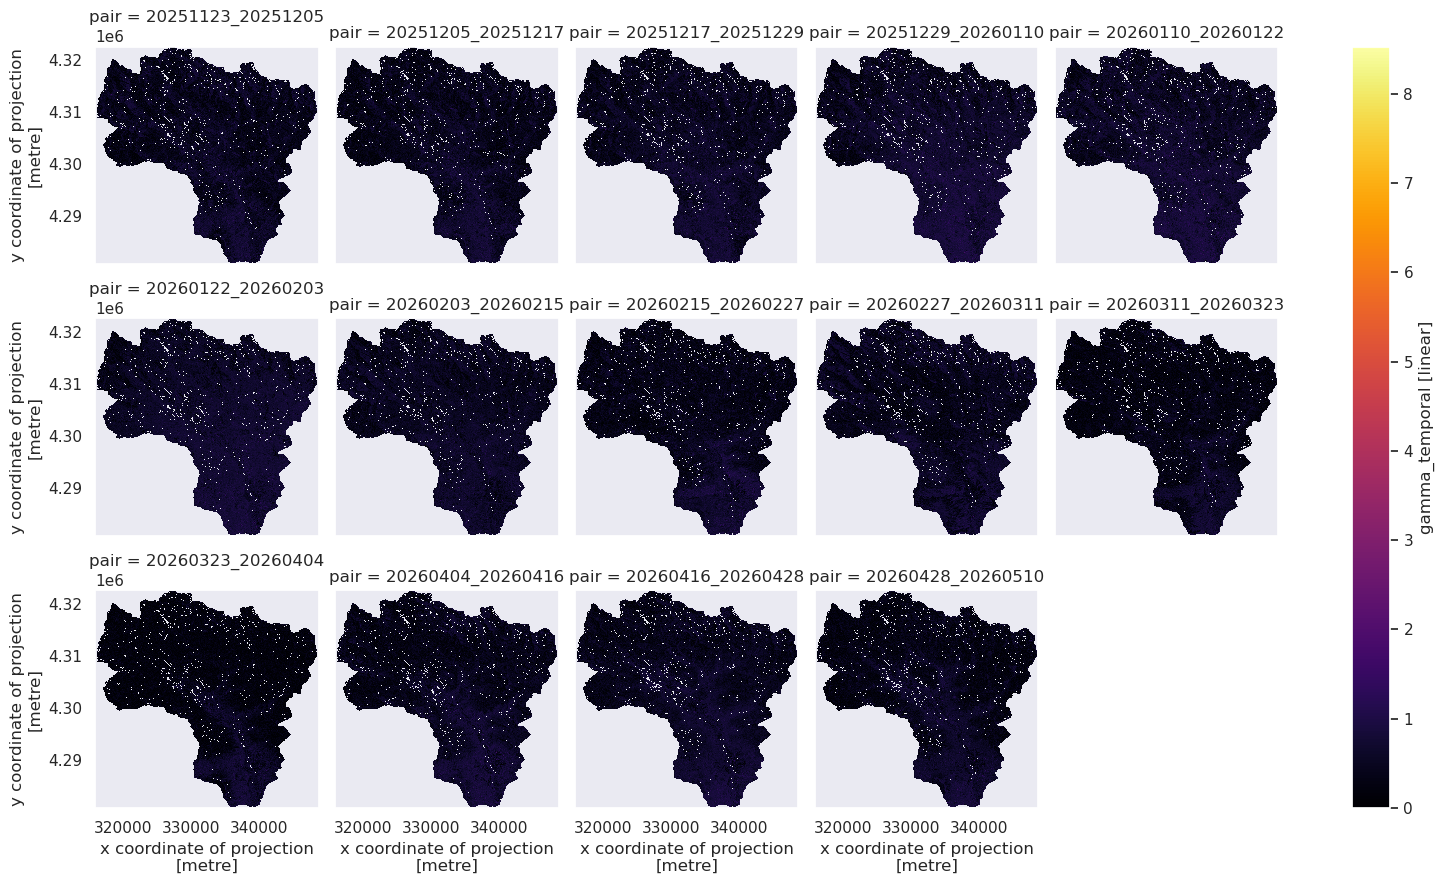

In [23]:
nisar_80m['gamma_temporal'].plot(col='pair', col_wrap=5, cmap='inferno')
nisar_20m['gamma_temporal'].plot(col='pair', col_wrap=5, cmap='inferno')

Save the zarrs. 

In [ ]:
# snr.to_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/snr.zarr', mode="w")
# gamma_thermal.to_dataset(name='gamma_thermal').to_zarr(data_dir + 'nisar/zarrs/gamma_thermal.zarr', mode="w")
# gamma_spatial.to_dataset(name='gamma_spatial').to_zarr(data_dir + 'nisar/zarrs/gamma_spatial.zarr', mode="w")
# nisar_20m.to_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/coherence_20m.zarr', mode="w")
nisar_80m.to_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/coherence_80m.zarr', mode="w")

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=17, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
